# CSET343 – AI in Healthcare
## Lab Assignment 6: CNN for Automated Diagnosis of Heart/Chest Disease (Pneumonia Detection)

**Dataset:** Chest X-Ray Images (Normal vs. Pneumonia) — `paultimothymooney/chest-xray-pneumonia` on Kaggle (~5,863 images)



### Setup — Install Required Packages

In [1]:
!pip install -q kagglehub scikit-learn scikit-image pandas numpy matplotlib seaborn opencv-python


In [2]:
import os
import glob
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

IMG_SIZE = 128  # resize dimension as required by Task 2


### GPU Check (Colab)

In [3]:
# Verify TensorFlow can see the GPU, and enable memory growth so it doesn't
# grab all GPU memory up front. Run this BEFORE any model building/training below.
gpus = tf.config.list_physical_devices("GPU")
print("GPUs detected:", gpus)

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled — training below will run on GPU.")
    except RuntimeError as e:
        print("Could not set memory growth (must be set before GPUs are initialized):", e)
else:
    print("No GPU detected by TensorFlow. On Kaggle: open the notebook settings panel "
          "(right sidebar) > Accelerator > choose a GPU (e.g. GPU T4 x2 / P100), save, "
          "then re-run all cells from the top.")


GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Memory growth enabled — training below will run on GPU.



## Task 1: Data Acquisition and Exploration


###  Download and Load the Dataset

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)


Path to dataset files: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia


In [5]:
# Explore the folder structure
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    if level >= 2:
        # don't print every single filename, just a count
        if files:
            print(f"{indent}  ({len(files)} files)")
        dirs[:] = []  # stop descending further


chest-xray-pneumonia/
  chest_xray/
    chest_xray/
      (1 files)
    __MACOSX/
      (1 files)
    val/
    test/
    train/


In [6]:
# The Kaggle dataset ships with its own train/val/test split, but the official 'val'
# folder only has 16 images (too small to be useful), so we pool ALL images together
# here and build our own proper stratified 70/15/15 split in Task 2.
image_paths = []
labels = []

for split in ["train", "test", "val"]:
    split_dir = os.path.join(path, "chest_xray", split)
    if not os.path.isdir(split_dir):
        continue
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            if fname.lower().endswith((".jpeg", ".jpg", ".png")):
                image_paths.append(os.path.join(class_dir, fname))
                labels.append(class_name)

data_df = pd.DataFrame({"filepath": image_paths, "label": labels})
print("Total images found:", len(data_df))
data_df.head()


Total images found: 5856


,filepath,label
0,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL
1,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL
2,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL
3,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL
4,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL


### Display Random Sample Images per Class

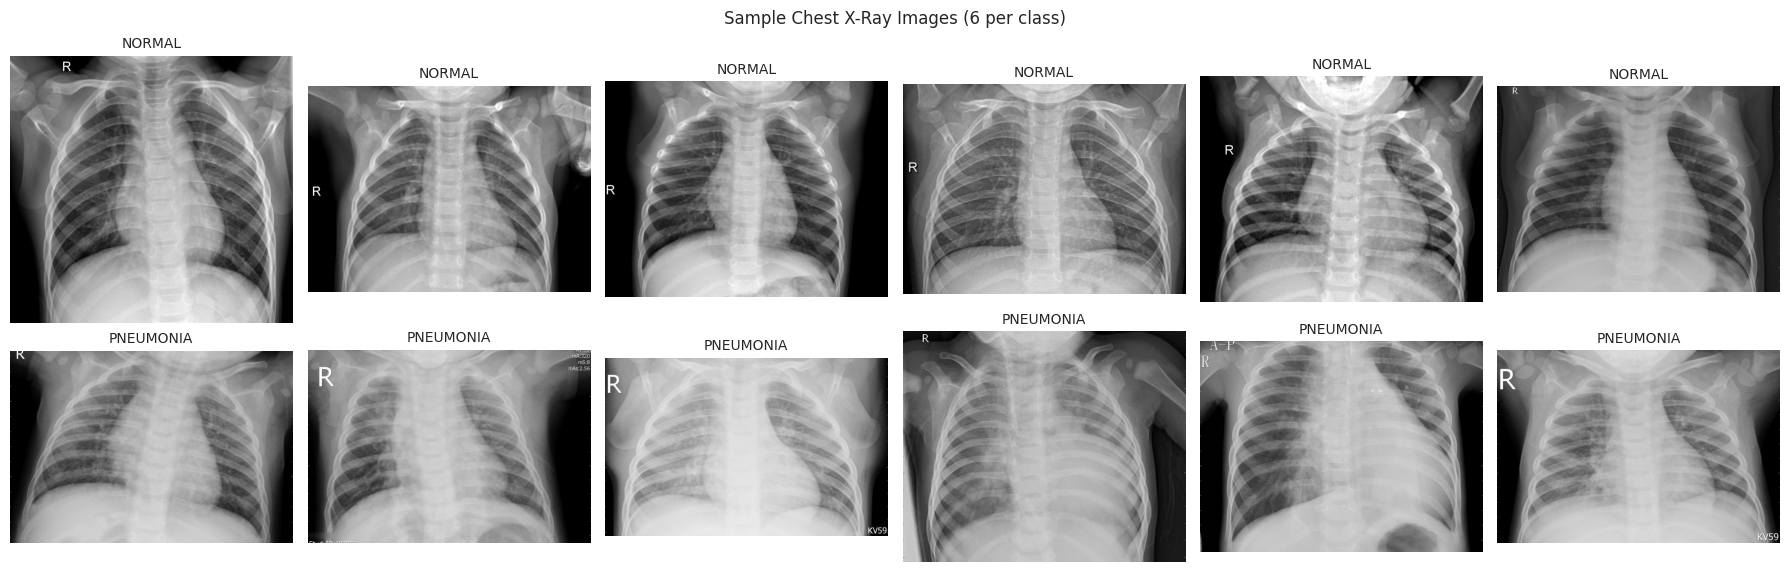

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))

for row, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    sample_paths = data_df[data_df["label"] == class_name]["filepath"].sample(6, random_state=RANDOM_STATE).tolist()
    for col, img_path in enumerate(sample_paths):
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name, fontsize=10)
        axes[row, col].axis("off")

plt.suptitle("Sample Chest X-Ray Images (6 per class)")
plt.tight_layout()
plt.show()


### Class Balance

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64


/tmp/ipykernel_49/3115941211.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")


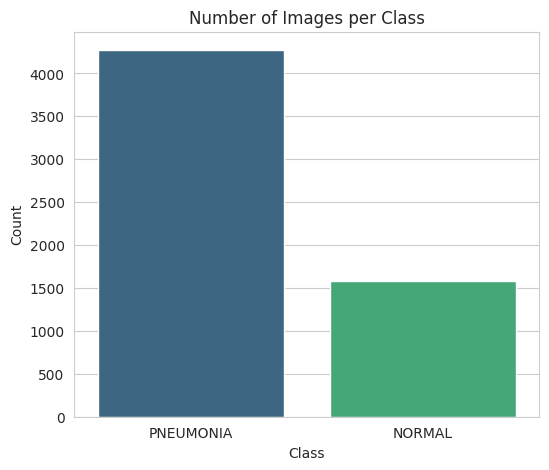


Class balance: {'PNEUMONIA': 72.97, 'NORMAL': 27.03}


In [8]:
class_counts = data_df["label"].value_counts()
print(class_counts)

plt.figure(figsize=(6, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

print(f"\nClass balance: {(class_counts / class_counts.sum() * 100).round(2).to_dict()}")


## Task 2: Data Preprocessing

### 2 Train / Validation / Test Split (70% / 15% / 15%, Stratified)

In [9]:
train_df, temp_df = train_test_split(
    data_df, test_size=0.30, stratify=data_df["label"], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape, dict(train_df["label"].value_counts()))
print("Val:  ", val_df.shape, dict(val_df["label"].value_counts()))
print("Test: ", test_df.shape, dict(test_df["label"].value_counts()))


Train: (4099, 2) {'PNEUMONIA': np.int64(2991), 'NORMAL': np.int64(1108)}
Val:   (878, 2) {'PNEUMONIA': np.int64(641), 'NORMAL': np.int64(237)}
Test:  (879, 2) {'PNEUMONIA': np.int64(641), 'NORMAL': np.int64(238)}


### Resize + Grayscale Helper

Resized image shape: (128, 128) | dtype: uint8


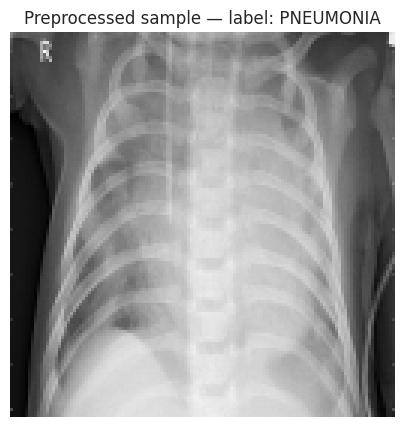

In [10]:
def load_and_preprocess_image(filepath, img_size=IMG_SIZE):
    """Reads an image, converts to grayscale, resizes to (img_size, img_size),
    and returns a uint8 array (0-255) suitable for both feature extraction and CNN input."""
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    return img

# Quick sanity check
sample_img = load_and_preprocess_image(train_df.loc[0, "filepath"])
print("Resized image shape:", sample_img.shape, "| dtype:", sample_img.dtype)
plt.imshow(sample_img, cmap="gray")
plt.title(f"Preprocessed sample — label: {train_df.loc[0, 'label']}")
plt.axis("off")
plt.show()


### Feature Extraction: HOG, LBP, GLCM

In [11]:
def extract_hog_features(gray_img):
    features = hog(
        gray_img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True,
    )
    return features


def extract_lbp_features(gray_img, P=8, R=1):
    lbp = local_binary_pattern(gray_img, P=P, R=R, method="uniform")
    n_bins = P + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist


def extract_glcm_features(gray_img, distances=(1,), angles=(0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)):
    glcm = graycomatrix(
        gray_img, distances=list(distances), angles=list(angles),
        levels=256, symmetric=True, normed=True
    )
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    # average each property over all distances/angles to get a compact feature vector
    feats = [graycoprops(glcm, p).mean() for p in props]
    return np.array(feats)


def extract_combined_features(gray_img):
    hog_feat = extract_hog_features(gray_img)
    lbp_feat = extract_lbp_features(gray_img)
    glcm_feat = extract_glcm_features(gray_img)
    return np.concatenate([hog_feat, lbp_feat, glcm_feat])

# Quick sanity check on feature sizes
_f = extract_combined_features(sample_img)
print("HOG + LBP + GLCM combined feature vector length:", _f.shape[0])


HOG + LBP + GLCM combined feature vector length: 8116


### Build Feature Vectors and Image Arrays for Each Split

In [12]:
def build_dataset(df, img_size=IMG_SIZE, extract_features=True):
    """Returns (image_array, feature_array, labels) for a given dataframe of filepaths/labels."""
    images = []
    feats = []
    for fp in df["filepath"]:
        gray = load_and_preprocess_image(fp, img_size)
        images.append(gray)
        if extract_features:
            feats.append(extract_combined_features(gray))

    images = np.array(images, dtype=np.float32) / 255.0  # normalize to [0, 1] for the CNN
    images = images[..., np.newaxis]  # add channel dimension -> (N, H, W, 1)
    feats = np.array(feats, dtype=np.float32) if extract_features else None
    labels = df["label"].values
    return images, feats, labels

print("Building train set...")
X_train_img, X_train_feat, y_train_raw = build_dataset(train_df)
print("Building validation set...")
X_val_img, X_val_feat, y_val_raw = build_dataset(val_df)
print("Building test set...")
X_test_img, X_test_feat, y_test_raw = build_dataset(test_df)

print("\nImage array shapes:", X_train_img.shape, X_val_img.shape, X_test_img.shape)
print("Feature array shapes:", X_train_feat.shape, X_val_feat.shape, X_test_feat.shape)


Building train set...
Building test set...

Image array shapes: (4099, 128, 128, 1) (878, 128, 128, 1) (879, 128, 128, 1)
Feature array shapes: (4099, 8116) (878, 8116) (879, 8116)


In [13]:
# Encode labels (NORMAL=0, PNEUMONIA=1) and scale engineered features
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_val = label_encoder.transform(y_val_raw)
y_test = label_encoder.transform(y_test_raw)

print("Classes:", list(label_encoder.classes_))

feat_scaler = StandardScaler()
X_train_feat_scaled = feat_scaler.fit_transform(X_train_feat)
X_val_feat_scaled = feat_scaler.transform(X_val_feat)
X_test_feat_scaled = feat_scaler.transform(X_test_feat)


Classes: ['NORMAL', 'PNEUMONIA']



## Task 3: Model Training and Basic Evaluation


### Baseline Models (Classical ML on HOG + LBP + GLCM Features)

These use the engineered feature vectors from Task 2 as baselines to compare against the CNN. Hyperparameters are tuned with GridSearchCV (built-in cross-validation).

In [14]:
baseline_param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"C": [0.01, 0.1, 1, 10]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [200, 400], "max_depth": [None, 20]},
    ),
    "SVM (RBF)": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"C": [1, 10], "gamma": ["scale", "auto"]},
    ),
}

baseline_models = {}

for name, (estimator, param_grid) in baseline_param_grids.items():
    print(f"Tuning {name} with 5-fold cross-validation...")
    grid = GridSearchCV(estimator, param_grid, cv=5, scoring="f1_macro", n_jobs=-1)
    grid.fit(X_train_feat_scaled, y_train)
    baseline_models[name] = grid.best_estimator_
    print(f"  Best params: {grid.best_params_}  |  Best CV F1 (macro): {grid.best_score_:.4f}\n")


Tuning Logistic Regression with 5-fold cross-validation...
  Best params: {'C': 0.01}  |  Best CV F1 (macro): 0.9450

Tuning Random Forest with 5-fold cross-validation...
  Best params: {'max_depth': None, 'n_estimators': 200}  |  Best CV F1 (macro): 0.9216

Tuning SVM (RBF) with 5-fold cross-validation...
  Best params: {'C': 10, 'gamma': 'scale'}  |  Best CV F1 (macro): 0.9497



### CNN Model (Raw Images)

In [15]:
def build_cnn(learning_rate=1e-3, dropout_rate=0.3):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model

build_cnn().summary()


I0000 00:00:1791189226.216169      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791189226.221495      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,129 (16.36 MB)

 Trainable params: 4,287,681 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

###  Hyperparameter Tuning (via Validation Set)



In [16]:
param_grid_cnn = [
    {"learning_rate": 1e-3, "dropout_rate": 0.3},
    {"learning_rate": 1e-3, "dropout_rate": 0.5},
    {"learning_rate": 1e-4, "dropout_rate": 0.3},
]

tuning_results = []

for params in param_grid_cnn:
    print(f"Trying params: {params}")
    model = build_cnn(**params)
    history = model.fit(
        X_train_img, y_train,
        validation_data=(X_val_img, y_val),
        epochs=5,
        batch_size=32,
        verbose=0,
    )
    val_auc = history.history["val_auc"][-1]
    val_acc = history.history["val_accuracy"][-1]
    tuning_results.append({**params, "val_accuracy": val_acc, "val_auc": val_auc})
    print(f"  val_accuracy={val_acc:.4f}  val_auc={val_auc:.4f}\n")

tuning_df = pd.DataFrame(tuning_results).sort_values("val_auc", ascending=False)
tuning_df


Trying params: {'learning_rate': 0.001, 'dropout_rate': 0.3}


I0000 00:00:1791189236.937311     183 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  val_accuracy=0.8759  val_auc=0.9569

Trying params: {'learning_rate': 0.001, 'dropout_rate': 0.5}
  val_accuracy=0.8667  val_auc=0.9761

Trying params: {'learning_rate': 0.0001, 'dropout_rate': 0.3}
  val_accuracy=0.9476  val_auc=0.9872



,learning_rate,dropout_rate,val_accuracy,val_auc
2,0.0001,0.3,0.947608,0.987174
1,0.0010,0.5,0.866743,0.976099
0,0.0010,0.3,0.875854,0.956907


In [17]:
best_params = tuning_df.iloc[0][["learning_rate", "dropout_rate"]].to_dict()
print("Best hyperparameters selected:", best_params)


Best hyperparameters selected: {'learning_rate': 0.0001, 'dropout_rate': 0.3}


### Train Final CNN with Best Hyperparameters

### GPU Check — Immediately Before Training

In [18]:
# Explicit check right before the heavy training step. If this prints no GPU,
# STOP and fix the Kaggle accelerator setting (see note above) before continuing —
# training ~4,100 images on CPU is what causes the long runtimes/overheating.
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print(f"Training on GPU: {gpus}")
else:
    print("WARNING: No GPU detected — this will run on CPU and be very slow. "
          "Go to Kaggle notebook Settings > Accelerator > GPU, save, and restart the session.")

assert len(gpus) > 0, "No GPU available — enable a GPU accelerator in Kaggle notebook settings and restart."


Training on GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [19]:
cnn_model = build_cnn(**best_params)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

history = cnn_model.fit(
    X_train_img, y_train,
    validation_data=(X_val_img, y_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.9156 - auc: 0.9586 - loss: 0.2387 - val_accuracy: 0.7301 - val_auc: 0.5000 - val_loss: 2.1081 - learning_rate: 1.0000e-04
Epoch 2/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9546 - auc: 0.9848 - loss: 0.1302 - val_accuracy: 0.7301 - val_auc: 0.5000 - val_loss: 2.9423 - learning_rate: 1.0000e-04
Epoch 3/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9666 - auc: 0.9915 - loss: 0.0967 - val_accuracy: 0.7312 - val_auc: 0.7210 - val_loss: 1.6595 - learning_rate: 1.0000e-04
Epoch 4/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9712 - auc: 0.9939 - loss: 0.0814 - val_accuracy: 0.8770 - val_auc: 0.9483 - val_loss: 0.4274 - learning_rate: 1.0000e-04
Epoch 5/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9780 - auc: 0.9965 - loss: 0.0587 - val_accuracy: 0.9214 - val_auc: 0.9798 - val_loss: 0.2186 - learning_rate: 1.0000e-04
Epoch 6/30
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step -

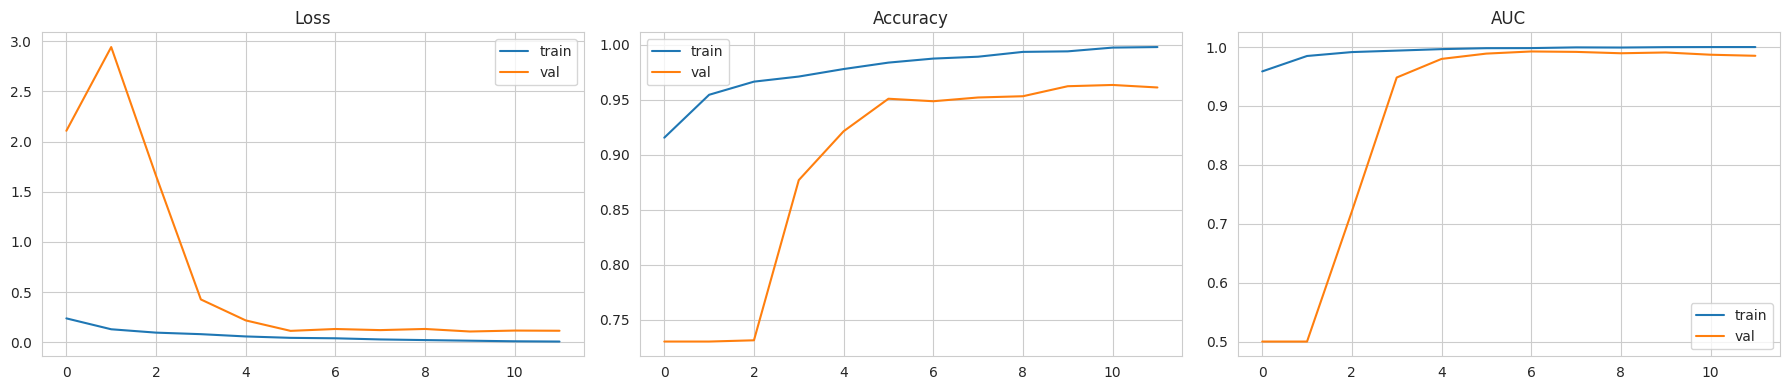

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()

axes[2].plot(history.history["auc"], label="train")
axes[2].plot(history.history["val_auc"], label="val")
axes[2].set_title("AUC"); axes[2].legend()

plt.tight_layout()
plt.show()


### Evaluate All Models on the Test Set

In [21]:
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "AUROC": roc_auc_score(y_true, y_proba),
    }

all_results = []
all_predictions = {}
all_probabilities = {}

# --- CNN ---
cnn_proba = cnn_model.predict(X_test_img, verbose=0).ravel()
cnn_pred = (cnn_proba >= 0.5).astype(int)
all_predictions["CNN"] = cnn_pred
all_probabilities["CNN"] = cnn_proba
all_results.append(evaluate_model("CNN", y_test, cnn_pred, cnn_proba))

# --- Baseline classical ML models ---
for name, model in baseline_models.items():
    pred = model.predict(X_test_feat_scaled)
    proba = model.predict_proba(X_test_feat_scaled)[:, 1]
    all_predictions[name] = pred
    all_probabilities[name] = proba
    all_results.append(evaluate_model(name, y_test, pred, proba))

results_df = pd.DataFrame(all_results).set_index("Model").round(4)
results_df.sort_values("F1-score", ascending=False)


,Accuracy,Precision,Recall,F1-score,AUROC
Model,,,,,
SVM (RBF),0.9590,0.9604,0.9844,0.9723,0.9885
Logistic Regression,0.9579,0.9689,0.9735,0.9712,0.9872
CNN,0.9556,0.9855,0.9532,0.9691,0.9911
Random Forest,0.9340,0.9464,0.9641,0.9552,0.9749


In [22]:
for name in all_predictions:
    print(f"\n===== {name} — Classification Report =====")
    print(classification_report(y_test, all_predictions[name], target_names=label_encoder.classes_, zero_division=0))



===== CNN — Classification Report =====
              precision    recall  f1-score   support

      NORMAL       0.88      0.96      0.92       238
   PNEUMONIA       0.99      0.95      0.97       641

    accuracy                           0.96       879
   macro avg       0.93      0.96      0.95       879
weighted avg       0.96      0.96      0.96       879


===== Logistic Regression — Classification Report =====
              precision    recall  f1-score   support

      NORMAL       0.93      0.92      0.92       238
   PNEUMONIA       0.97      0.97      0.97       641

    accuracy                           0.96       879
   macro avg       0.95      0.94      0.95       879
weighted avg       0.96      0.96      0.96       879


===== Random Forest — Classification Report =====
              precision    recall  f1-score   support

      NORMAL       0.90      0.85      0.88       238
   PNEUMONIA       0.95      0.96      0.96       641

    accuracy                     

###  Confusion Matrices

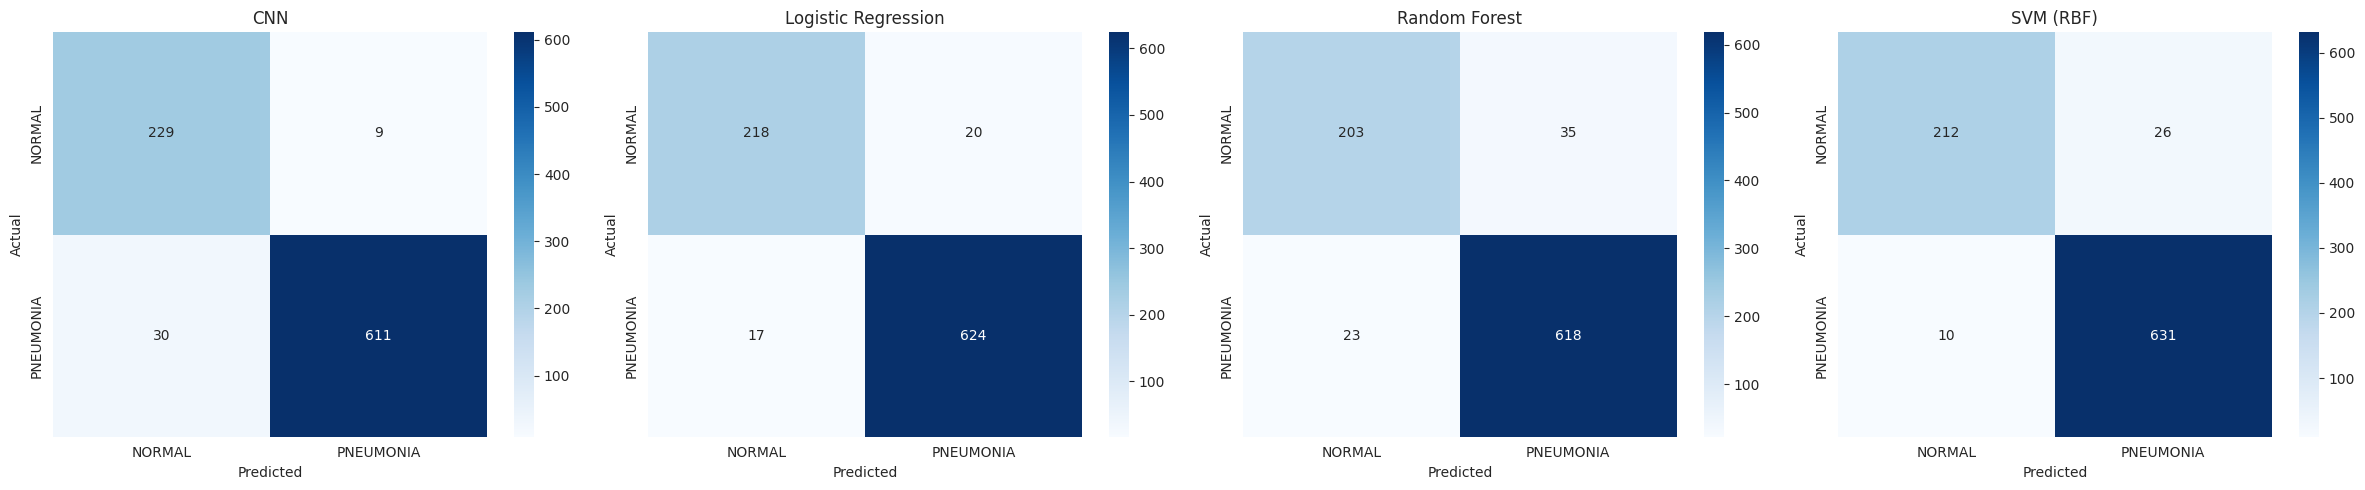

In [23]:
model_names = list(all_predictions.keys())
fig, axes = plt.subplots(1, len(model_names), figsize=(6 * len(model_names), 5))
if len(model_names) == 1:
    axes = [axes]

for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_test, all_predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


### ROC Curves

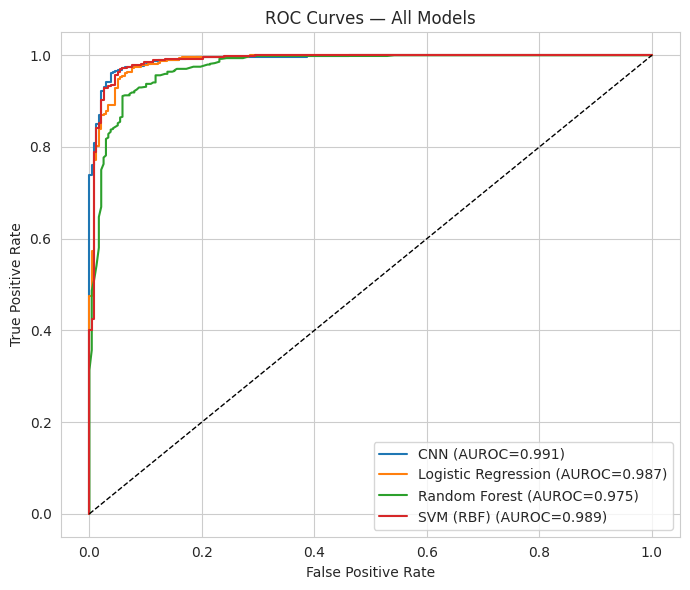

In [24]:
plt.figure(figsize=(7, 6))
for name in model_names:
    fpr, tpr, _ = roc_curve(y_test, all_probabilities[name])
    auc_score = roc_auc_score(y_test, all_probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUROC={auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend()
plt.tight_layout()
plt.show()


###  Explaining Misclassifications (CNN)

Number of CNN misclassifications: 39 / 879


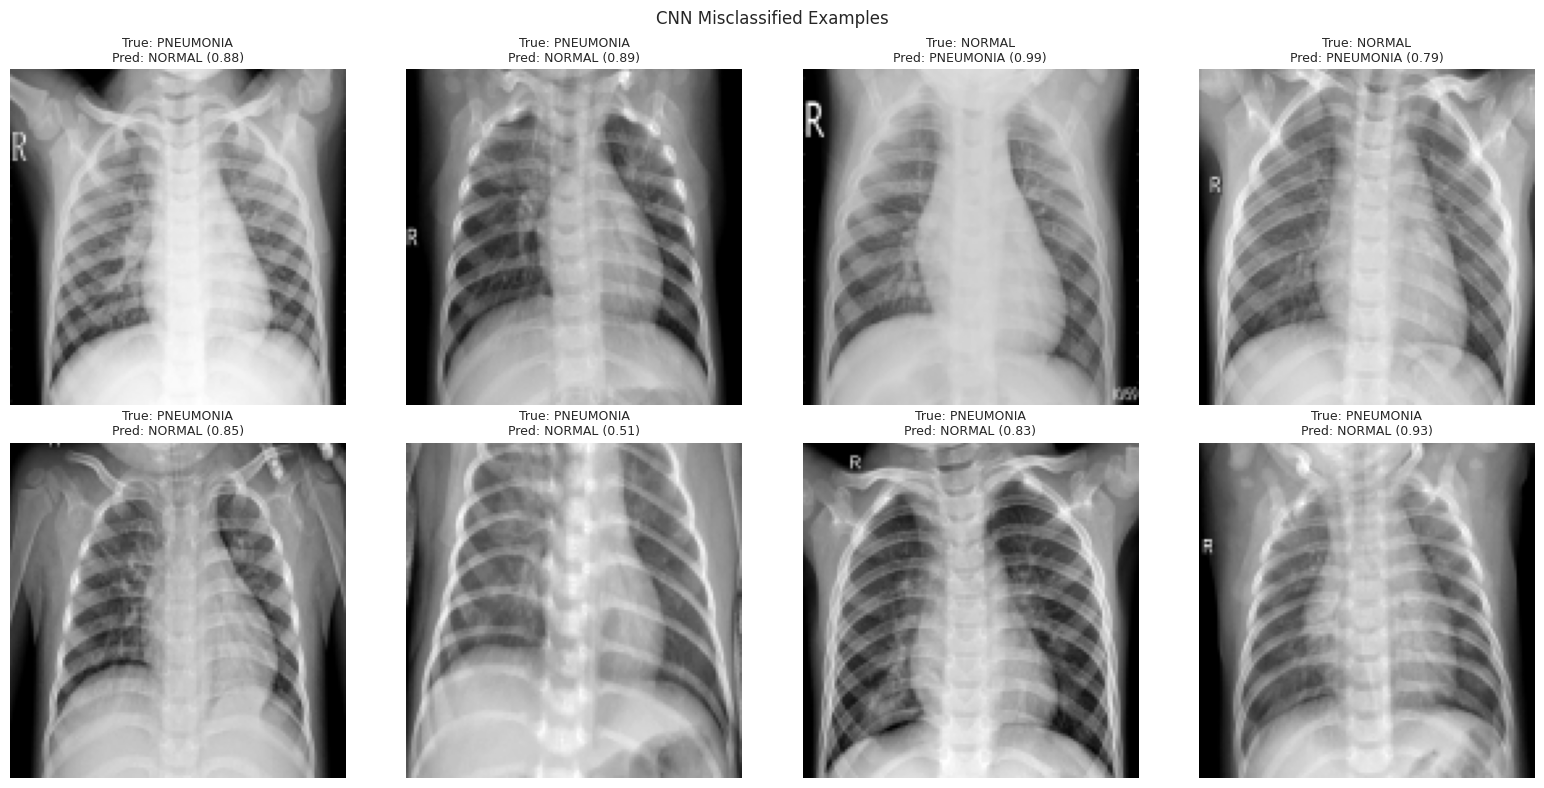

In [25]:
misclassified_idx = np.where(cnn_pred != y_test)[0]
print(f"Number of CNN misclassifications: {len(misclassified_idx)} / {len(y_test)}")

n_show = min(8, len(misclassified_idx))
show_idx = np.random.choice(misclassified_idx, n_show, replace=False) if n_show > 0 else []

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, show_idx):
    ax.imshow(X_test_img[idx].squeeze(), cmap="gray")
    true_label = label_encoder.classes_[y_test[idx]]
    pred_label = label_encoder.classes_[cnn_pred[idx]]
    confidence = cnn_proba[idx] if cnn_pred[idx] == 1 else 1 - cnn_proba[idx]
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.2f})", fontsize=9)
    ax.axis("off")

for ax in axes[len(show_idx):]:
    ax.axis("off")

plt.suptitle("CNN Misclassified Examples")
plt.tight_layout()
plt.show()


### 3.9 Final Comparison and Interpretation

In [26]:
results_df.sort_values("AUROC", ascending=False)


,Accuracy,Precision,Recall,F1-score,AUROC
Model,,,,,
CNN,0.9556,0.9855,0.9532,0.9691,0.9911
SVM (RBF),0.9590,0.9604,0.9844,0.9723,0.9885
Logistic Regression,0.9579,0.9689,0.9735,0.9712,0.9872
Random Forest,0.9340,0.9464,0.9641,0.9552,0.9749
